# EX5 EDA on Airlines Delay Data

#### We will conduct basic EDA on airlines delays datasets.

- Conduct basic preprocessing

- Apply EDA on chosen data


#### Airlines delay datasets

- Flight delay explanatory data analysis using airlines delay datasets

https://www.kaggle.com/giovamata/airlinedelaycauses

- EDA examples:

https://www.kaggle.com/adveros/flight-delay-eda-exploratory-data-analysis

- a complete report of airlines delay can be found in Canvas Week 4.

### Part 0:
    
- Examples below are the EDA for airlines delays 2020 data

- Run through the code and check preprocessing and some tools of EDA.

In [44]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [45]:
data = pd.read_csv('/content/airtrans_2015_Jan.csv')
# if there are any missing values, then fill in with NaN
data = data.fillna(np.nan)
data.head()

,flight_date,unique_carrier,flight_num,origin,dest,dep_delay,arr_delay,cancelled,actual_elapsed_time,distance,carrier_delay,weather_delay,late_aircraft_dealy
0,1/1/15,AA,363,LGA,ORD,-6.0,-22.0,0,144.0,733,NaN,NaN,NaN
1,1/1/15,AA,364,ORD,LGA,-4.0,-11.0,0,113.0,733,NaN,NaN,NaN
2,1/1/15,AA,365,DCA,DFW,24.0,37.0,0,223.0,1192,24.0,0.0,0.0
3,1/1/15,AA,366,ORD,LGA,0.0,1.0,0,121.0,733,NaN,NaN,NaN
4,1/1/15,AA,367,TUL,DFW,NaN,NaN,1,NaN,237,NaN,NaN,NaN


#### Python lambda

- see the examples of lambda

https://www.w3schools.com/python/python_lambda.asp

In [46]:
# add a new column with 'delayed' as key with values either True or False
data['delayed'] = data['arr_delay'].apply(lambda x: x > 0)

data.head()

,flight_date,unique_carrier,flight_num,origin,dest,dep_delay,arr_delay,cancelled,actual_elapsed_time,distance,carrier_delay,weather_delay,late_aircraft_dealy,delayed
0,1/1/15,AA,363,LGA,ORD,-6.0,-22.0,0,144.0,733,NaN,NaN,NaN,False
1,1/1/15,AA,364,ORD,LGA,-4.0,-11.0,0,113.0,733,NaN,NaN,NaN,False
2,1/1/15,AA,365,DCA,DFW,24.0,37.0,0,223.0,1192,24.0,0.0,0.0,True
3,1/1/15,AA,366,ORD,LGA,0.0,1.0,0,121.0,733,NaN,NaN,NaN,True
4,1/1/15,AA,367,TUL,DFW,NaN,NaN,1,NaN,237,NaN,NaN,NaN,False


In [47]:
# create a new DataFrame containing only delayed flights
delayed_flights = data[data['delayed'] == True]

delayed_flights.head()

,flight_date,unique_carrier,flight_num,origin,dest,dep_delay,arr_delay,cancelled,actual_elapsed_time,distance,carrier_delay,weather_delay,late_aircraft_dealy,delayed
2,1/1/15,AA,365,DCA,DFW,24.0,37.0,0,223.0,1192,24.0,0.0,0.0,True
3,1/1/15,AA,366,ORD,LGA,0.0,1.0,0,121.0,733,NaN,NaN,NaN,True
6,1/1/15,AA,369,DFW,SAN,12.0,20.0,0,193.0,1171,12.0,0.0,0.0,True
10,1/1/15,AA,371,SEA,MIA,-8.0,1.0,0,347.0,2724,NaN,NaN,NaN,True
11,1/1/15,AA,373,DFW,SAT,78.0,82.0,0,69.0,247,12.0,0.0,66.0,True


In [48]:
# how many unique carriers that have delayed flights
delayed_flights['unique_carrier'].value_counts()

,count
unique_carrier,
WN,37826
OO,20980
EV,20612
AA,17957
DL,17589
UA,15351
MQ,14823
US,12702
B6,8643


In [49]:
# retrieve flights with delayed information (False or True)
# group the data based on unique_carrier and count them.
delayed_by_carrier = data.groupby(['unique_carrier', 'delayed']).size().unstack()
delayed_by_carrier

delayed,False,True
unique_carrier,,
AA,26102,17957
AS,8795,4462
B6,12980,8643
DL,46832,17589
EV,29313,20612
F9,3286,3543
HA,3609,2831
MQ,15077,14823
NK,4627,4116


In [50]:
# set default index (0, 1, 2, 3, ...)

delayed_by_carrier = delayed_by_carrier.reset_index()
delayed_by_carrier[:5]

delayed,unique_carrier,False,True
0,AA,26102,17957
1,AS,8795,4462
2,B6,12980,8643
3,DL,46832,17589
4,EV,29313,20612


In [51]:
# add a new column of the total flights
delayed_by_carrier['flight_count'] = delayed_by_carrier[False] + delayed_by_carrier[True]

# display top 5 rows
delayed_by_carrier[:5]

delayed,unique_carrier,False,True,flight_count
0,AA,26102,17957,44059
1,AS,8795,4462,13257
2,B6,12980,8643,21623
3,DL,46832,17589,64421
4,EV,29313,20612,49925


In [52]:
# calculate the ratio of delayed flights
delayed_by_carrier['proportion_delayed'] = delayed_by_carrier[True] / delayed_by_carrier['flight_count']

# display top 5 rows
delayed_by_carrier[:5]

delayed,unique_carrier,False,True,flight_count,proportion_delayed
0,AA,26102,17957,44059,0.407567
1,AS,8795,4462,13257,0.336577
2,B6,12980,8643,21623,0.399713
3,DL,46832,17589,64421,0.273032
4,EV,29313,20612,49925,0.412859


In [53]:
# sort the data
delayed_by_carrier.sort_values('proportion_delayed', ascending=False)

delayed,unique_carrier,False,True,flight_count,proportion_delayed
5,F9,3286,3543,6829,0.518817
7,MQ,15077,14823,29900,0.495753
8,NK,4627,4116,8743,0.470777
6,HA,3609,2831,6440,0.439596
9,OO,27134,20980,48114,0.436048
4,EV,29313,20612,49925,0.412859
0,AA,26102,17957,44059,0.407567
10,UA,23044,15351,38395,0.399818
2,B6,12980,8643,21623,0.399713
11,US,20787,12702,33489,0.379289


### pivot_table()

- see examples of pivot_table()

https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.pivot_table.html

In [54]:
data.pivot_table(columns='unique_carrier', values='arr_delay')

unique_carrier,AA,AS,B6,DL,EV,F9,HA,MQ,NK,OO,UA,US,VX,WN
arr_delay,6.955843,-0.320888,7.347281,-2.043847,8.537497,18.357238,3.51264,18.164974,11.398054,10.889894,6.352729,3.107457,1.420702,3.389466


In [55]:
# retrieve the information of arrival delay of South West
southwest = data[data['unique_carrier'] == 'WN']['arr_delay']
southwest.head()

,arr_delay
3258,-6.0
3259,-15.0
3260,14.0
3261,0.0
3262,-20.0


In [56]:
southwest.describe()

,arr_delay
count,98060.000000
mean,3.389466
std,30.186345
min,-63.000000
25%,-12.000000
50%,-4.000000
75%,9.000000
max,593.000000


count: there are 42,020 rows in the dataset, which is filtered to only show Southwest (WN).

mean: the average delay.
std: the standard deviation. More on this below.

min: the shortest delay in the dataset. In this case, the flight was very early.

25%: the 25th percentile. 25% of delays were lower than -9.00.

50%: the 50th percentile, or the median. 50% of delays were lower than 1.00.

75%: the 75th percentile. 75% of delays were lower than 19.00.

max: the longest delay in the dataset: 535.00.

In [57]:
wn_carrier = data[data['unique_carrier'] == 'WN']
wn_carrier['arr_delay'][:5]

,arr_delay
3258,-6.0
3259,-15.0
3260,14.0
3261,0.0
3262,-20.0


### Another way to plot box plots and histograms

<Axes: >

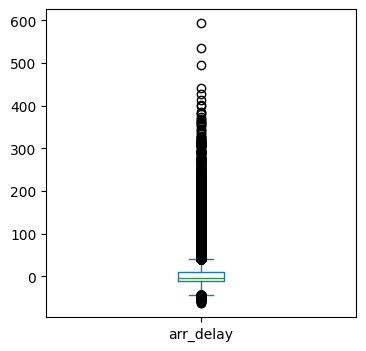

In [58]:
wn_carrier['arr_delay'].plot(kind='box', figsize=[4, 4])

<Axes: >

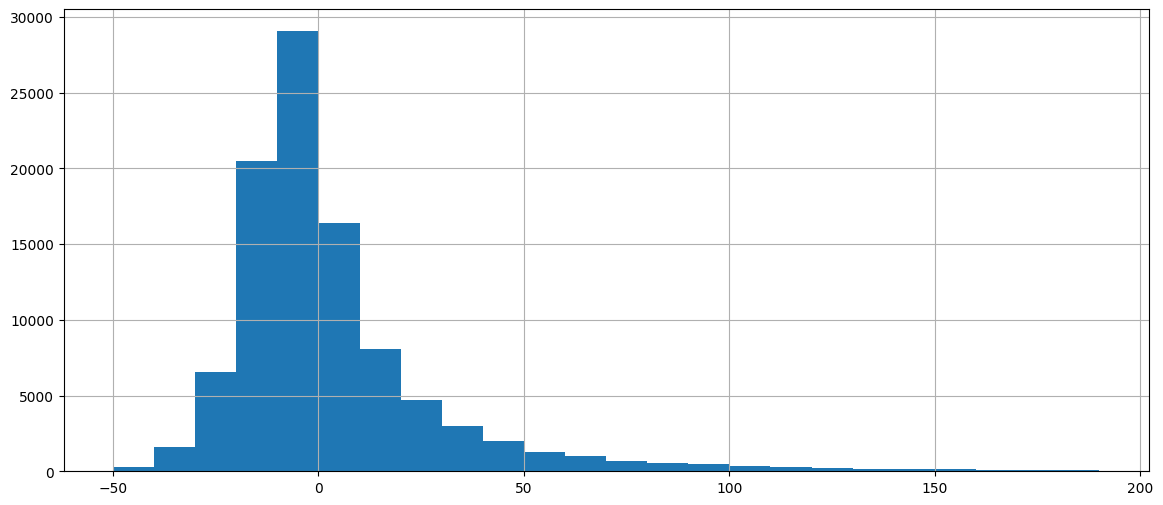

In [59]:
# histograms
bin_values = np.arange(start=-50, stop=200, step=10)
wn_carrier['arr_delay'].hist(bins=bin_values, figsize = [14, 6])

In [60]:
hi_volume = data['origin'].value_counts()[:20]
hi_volume.head()

,count
origin,
ATL,29512
ORD,23484
DFW,23153
LAX,17340
DEN,17090


In [61]:
hi_volume_airports_names = hi_volume.index.tolist()
hi_volume_airports_names

['ATL',
 'ORD',
 'DFW',
 'LAX',
 'DEN',
 'IAH',
 'PHX',
 'SFO',
 'LAS',
 'MCO',
 'LGA',
 'DTW',
 'CLT',
 'MSP',
 'BOS',
 'EWR',
 'SLC',
 'JFK',
 'SEA',
 'FLL']

## Part 1 Tasks

(1) Choose a dataset from the data repository of airlines delay.

(2) Conduct EDA on the data. This includes descriptive statistics and data visualization as shown in the above cells.

In [62]:
files = {'2015 Jan': '/content/airtrans_2015_Jan.csv', '2015 May': '/content/airtrans_2015_May.csv',
         '2020 Jan': '/content/airtrans_2020_Jan.csv', '2020 May': '/content/airtrans_2020_May.csv'}
frames = []
for label, f in files.items():
    d = pd.read_csv(f)
    d['period'] = label
    frames.append(d)
all_data = pd.concat(frames, ignore_index=True)
all_data = all_data.rename(columns={'late_aircraft_dealy': 'late_aircraft_delay'})  # fix typo in source column name
all_data['flight_date'] = pd.to_datetime(all_data['flight_date'], format='%m/%d/%y')
all_data['year'] = all_data['flight_date'].dt.year
all_data['delayed'] = all_data['arr_delay'] > 0          # same definition as Part 0
all_data['late15'] = all_data['arr_delay'] >= 15         # standard "official" delay threshold
order = ['2015 Jan', '2015 May', '2020 Jan', '2020 May']
print(all_data.shape)
all_data.head()

(1754924, 17)


,flight_date,unique_carrier,flight_num,origin,dest,dep_delay,arr_delay,cancelled,actual_elapsed_time,distance,carrier_delay,weather_delay,late_aircraft_delay,period,year,delayed,late15
0,2015-01-01,AA,363,LGA,ORD,-6.0,-22.0,0,144.0,733,NaN,NaN,NaN,2015 Jan,2015,False,False
1,2015-01-01,AA,364,ORD,LGA,-4.0,-11.0,0,113.0,733,NaN,NaN,NaN,2015 Jan,2015,False,False
2,2015-01-01,AA,365,DCA,DFW,24.0,37.0,0,223.0,1192,24.0,0.0,0.0,2015 Jan,2015,True,True
3,2015-01-01,AA,366,ORD,LGA,0.0,1.0,0,121.0,733,NaN,NaN,NaN,2015 Jan,2015,True,False
4,2015-01-01,AA,367,TUL,DFW,NaN,NaN,1,NaN,237,NaN,NaN,NaN,2015 Jan,2015,False,False


2. Data quality: missing values
Missing arr_delay mostly corresponds to cancelled/diverted flights. The three cause columns are only filled for flights delayed 15+ minutes, so they are not "missing at random".

In [63]:
print(all_data.isna().sum())
print()
print('arr_delay missing but not cancelled (likely diverted):', (all_data['arr_delay'].isna() & (all_data['cancelled'] == 0)).sum())
print('cause columns filled for flights with arr_delay < 15:', (all_data['carrier_delay'].notna() & (all_data['arr_delay'] < 15)).sum())

flight_date                  0
unique_carrier               0
flight_num                   0
origin                       0
dest                         0
dep_delay                35282
arr_delay                40355
cancelled                    0
actual_elapsed_time      40355
distance                     0
carrier_delay          1479249
weather_delay          1479249
late_aircraft_delay    1479249
period                       0
year                         0
delayed                      0
late15                       0
dtype: int64

arr_delay missing but not cancelled (likely diverted): 4138
cause columns filled for flights with arr_delay < 15: 0


In [64]:
#3. Descriptive statistics by period
g = all_data.groupby('period')
summary = pd.DataFrame({
    'flights': g.size(),
    'cancel_rate': g['cancelled'].mean(),
    'mean_arr_delay': g['arr_delay'].mean(),
    'median_arr_delay': g['arr_delay'].median(),
    'std_arr_delay': g['arr_delay'].std(),
    'max_arr_delay': g['arr_delay'].max(),
    'pct_delayed (>0)': g['arr_delay'].apply(lambda x: (x > 0).sum() / x.notna().sum()),
    'pct_late15 (>=15)': g['arr_delay'].apply(lambda x: (x >= 15).sum() / x.notna().sum()),
    'mean_distance': g['distance'].mean(),
}).loc[order]
summary.round(3)

,flights,cancel_rate,mean_arr_delay,median_arr_delay,std_arr_delay,max_arr_delay,pct_delayed (>0),pct_late15 (>=15),mean_distance
period,,,,,,,,,
2015 Jan,469968,0.025,5.814,-4.0,39.414,1971.0,0.401,0.210,803.261
2015 May,496993,0.011,4.485,-5.0,39.856,1480.0,0.358,0.183,823.323
2020 Jan,607346,0.011,-1.621,-10.0,45.016,2536.0,0.270,0.137,798.022
2020 May,180617,0.064,-11.472,-14.0,28.514,2093.0,0.125,0.046,713.232


In [65]:
all_data.groupby('period')['arr_delay'].describe().loc[order].round(2)

,count,mean,std,min,25%,50%,75%,max
period,,,,,,,,
2015 Jan,457013.0,5.81,39.41,-82.0,-13.0,-4.0,10.0,1971.0
2015 May,489641.0,4.49,39.86,-76.0,-13.0,-5.0,7.0,1480.0
2020 Jan,599268.0,-1.62,45.02,-96.0,-18.0,-10.0,2.0,2536.0
2020 May,168647.0,-11.47,28.51,-81.0,-22.0,-14.0,-7.0,2093.0


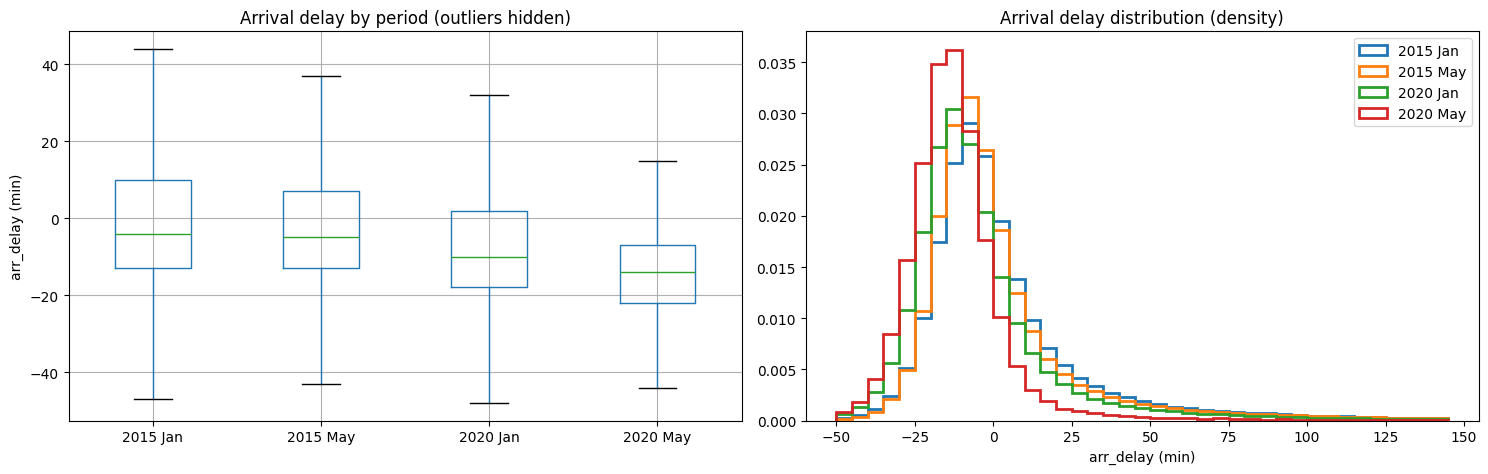

In [66]:
#4. Distribution of arrival delay: box plots and histograms
fig, ax = plt.subplots(1, 2, figsize=[15, 5])
all_data.boxplot(column='arr_delay', by='period', ax=ax[0], showfliers=False)
ax[0].set_title('Arrival delay by period (outliers hidden)'); ax[0].set_xlabel(''); ax[0].set_ylabel('arr_delay (min)')
bins = np.arange(-50, 150, 5)
for p in order:
    ax[1].hist(all_data.loc[all_data['period'] == p, 'arr_delay'].dropna(), bins=bins, density=True, histtype='step', linewidth=2, label=p)
ax[1].set_title('Arrival delay distribution (density)'); ax[1].set_xlabel('arr_delay (min)'); ax[1].legend()
plt.suptitle(''); plt.tight_layout(); plt.show()

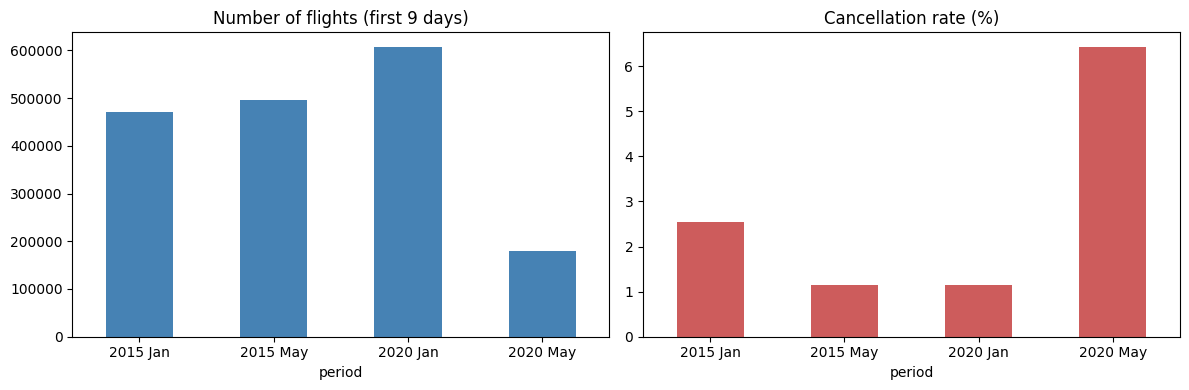

In [67]:
#5. Flights and cancellations
fig, ax = plt.subplots(1, 2, figsize=[12, 4])
summary['flights'].plot(kind='bar', ax=ax[0], color='steelblue', rot=0); ax[0].set_title('Number of flights (first 9 days)')
(summary['cancel_rate'] * 100).plot(kind='bar', ax=ax[1], color='indianred', rot=0); ax[1].set_title('Cancellation rate (%)')
plt.tight_layout(); plt.show()

In [68]:
#6. Carrier comparison (same approach as Part 0: groupby + unstack, proportion delayed
by_carrier = all_data.groupby(['unique_carrier', 'period']).agg(flights=('delayed', 'size'), mean_delay=('arr_delay', 'mean'),
                                                          prop_delayed=('delayed', 'mean')).reset_index()
pivot_prop = by_carrier.pivot(index='unique_carrier', columns='period', values='prop_delayed')[order]
pivot_prop.sort_values('2020 Jan', ascending=False).round(3)

period,2015 Jan,2015 May,2020 Jan,2020 May
unique_carrier,,,,
OH,NaN,NaN,0.388,0.113
AS,0.337,0.326,0.382,0.097
G4,NaN,NaN,0.359,0.133
MQ,0.496,0.342,0.341,0.166
HA,0.440,0.365,0.337,0.083
YV,NaN,NaN,0.319,0.138
AA,0.408,0.350,0.298,0.104
EV,0.413,0.370,0.282,0.138
B6,0.400,0.273,0.267,0.126


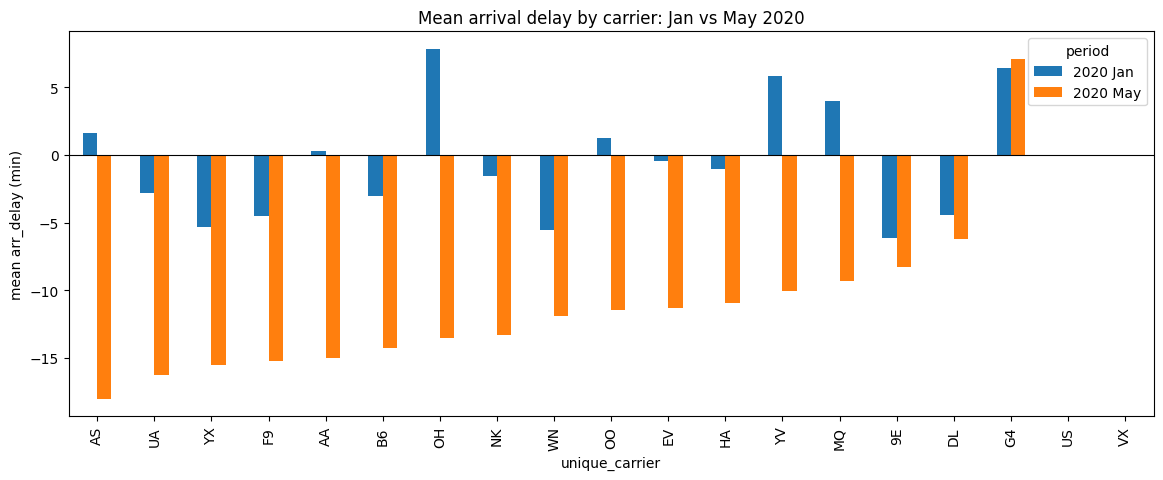

In [69]:
# mean arrival delay by carrier, Jan 2020 vs May 2020
pm = all_data.pivot_table(index='unique_carrier', columns='period', values='arr_delay')[['2020 Jan', '2020 May']].sort_values('2020 May')
pm.plot(kind='bar', figsize=[14, 5]); plt.ylabel('mean arr_delay (min)'); plt.title('Mean arrival delay by carrier: Jan vs May 2020'); plt.axhline(0, color='k', lw=0.8); plt.show()

In [70]:
# 2015 -> 2020 change for carriers present in both years (Jan only, comparable season)
both = all_data[all_data['period'].isin(['2015 Jan', '2020 Jan'])].pivot_table(index='unique_carrier', columns='period', values='arr_delay')
both = both.dropna(); both['change'] = both['2020 Jan'] - both['2015 Jan']
both.sort_values('change').round(2)

period,2015 Jan,2020 Jan,change
unique_carrier,,,
F9,18.36,-4.48,-22.84
MQ,18.16,3.95,-14.21
NK,11.40,-1.57,-12.97
B6,7.35,-3.00,-10.35
OO,10.89,1.27,-9.62
UA,6.35,-2.80,-9.15
WN,3.39,-5.59,-8.98
EV,8.54,-0.44,-8.97
AA,6.96,0.27,-6.68


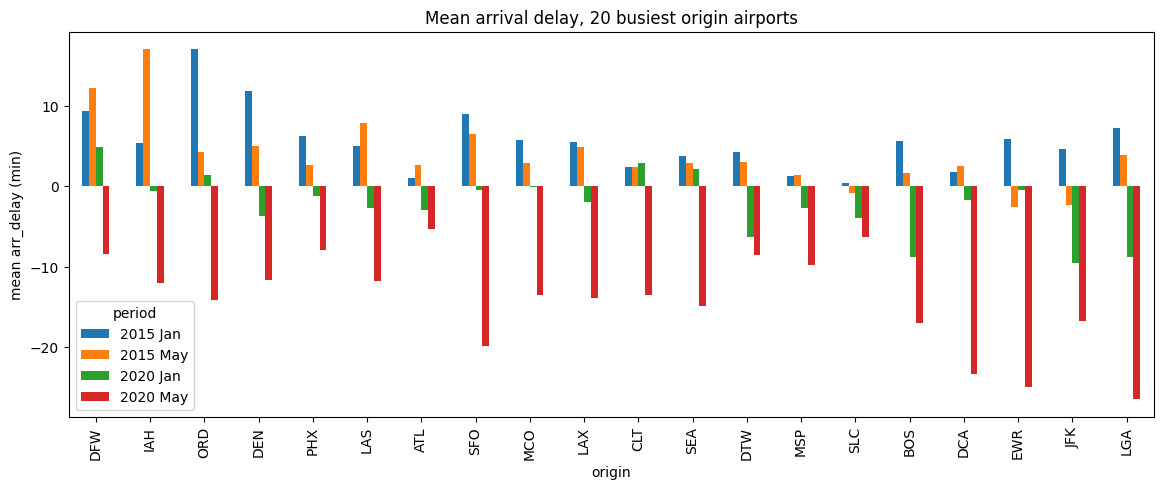

period,2015 Jan,2015 May,2020 Jan,2020 May
origin,,,,
DFW,9.4,12.2,4.9,-8.4
IAH,5.4,17.0,-0.5,-12.0
ORD,17.0,4.2,1.5,-14.2
DEN,11.8,5.0,-3.7,-11.7
PHX,6.2,2.6,-1.2,-7.9
LAS,5.1,7.9,-2.7,-11.8
ATL,1.1,2.7,-3.0,-5.3
SFO,9.0,6.4,-0.5,-19.9


In [71]:
#7. Airports: busiest origins and their delays
top20 = all_data['origin'].value_counts()[:20].index.tolist()
hv = all_data[all_data['origin'].isin(top20)]
ap = hv.pivot_table(index='origin', columns='period', values='arr_delay')[order]
ap['avg'] = ap.mean(axis=1)
ap = ap.sort_values('avg', ascending=False).drop(columns='avg')
ap.plot(kind='bar', figsize=[14, 5]); plt.ylabel('mean arr_delay (min)'); plt.title('Mean arrival delay, 20 busiest origin airports'); plt.show()
ap.round(1).head(8)

          dep_delay  arr_delay  distance  actual_elapsed_time
period                                                       
2015 Jan      0.938        1.0    -0.037                0.024
2015 May      0.947        1.0    -0.026                0.026
2020 Jan      0.954        1.0    -0.024                0.026
2020 May      0.924        1.0    -0.028                0.012


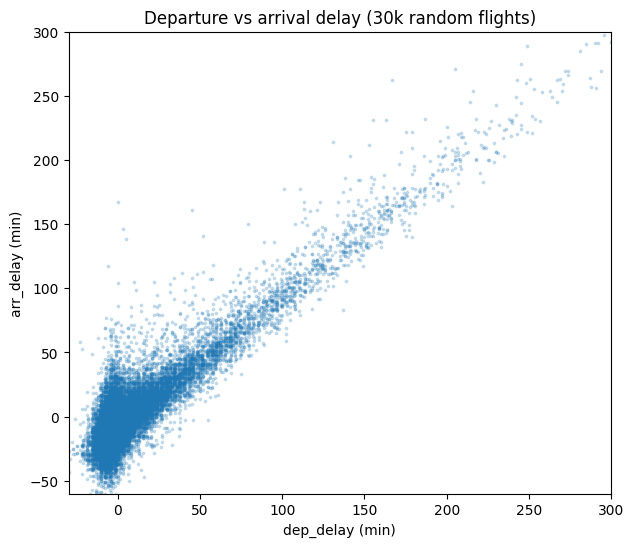

In [72]:
#8. Departure delay vs. arrival delay, and other correlations
valid = all_data.dropna(subset=['dep_delay', 'arr_delay'])
print(valid.groupby('period')[['dep_delay', 'arr_delay', 'distance', 'actual_elapsed_time']].corr().xs('arr_delay', level=1).round(3))
samp = valid.sample(30000, random_state=1)
plt.figure(figsize=[7, 6]); plt.scatter(samp['dep_delay'], samp['arr_delay'], s=3, alpha=0.2)
plt.xlim(-30, 300); plt.ylim(-60, 300); plt.xlabel('dep_delay (min)'); plt.ylabel('arr_delay (min)'); plt.title('Departure vs arrival delay (30k random flights)'); plt.show()

In [73]:
# does distance matter? mean delay by distance bucket
all_data['dist_bin'] = pd.cut(all_data['distance'], [0, 250, 500, 1000, 1500, 2500, 6000])
all_data.pivot_table(index='dist_bin', columns='period', values='arr_delay', observed=True)[order].round(2)

period,2015 Jan,2015 May,2020 Jan,2020 May
dist_bin,,,,
"(0, 250]",8.14,5.36,0.71,-10.91
"(250, 500]",6.36,5.56,-1.61,-11.65
"(500, 1000]",5.97,4.54,-1.48,-11.17
"(1000, 1500]",5.46,4.33,-1.97,-10.60
"(1500, 2500]",2.37,1.87,-4.39,-14.33
"(2500, 6000]",1.23,1.52,-3.03,-19.33


          carrier_delay  weather_delay  late_aircraft_delay
period                                                     
2015 Jan          17.80           2.74                22.76
2015 May          18.61           3.75                24.23
2020 Jan          24.70           4.59                20.56
2020 May          32.27           3.80                13.70

          carrier_delay  weather_delay  late_aircraft_delay
period                                                     
2015 Jan           41.1            6.3                 52.6
2015 May           39.9            8.1                 52.0
2020 Jan           49.5            9.2                 41.2
2020 May           64.8            7.6                 27.5


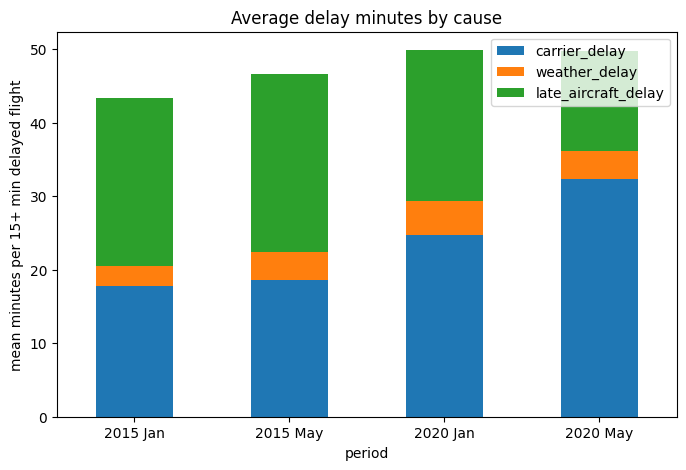

In [74]:
#9. Causes of delay (only available for flights delayed 15+ minutes)
causes = ['carrier_delay', 'weather_delay', 'late_aircraft_delay']
cm = all_data.groupby('period')[causes].mean().loc[order]
print(cm.round(2))
print()
print((cm.div(cm.sum(axis=1), axis=0) * 100).round(1))
cm.plot(kind='bar', stacked=True, figsize=[8, 5], rot=0); plt.ylabel('mean minutes per 15+ min delayed flight'); plt.title('Average delay minutes by cause'); plt.show()

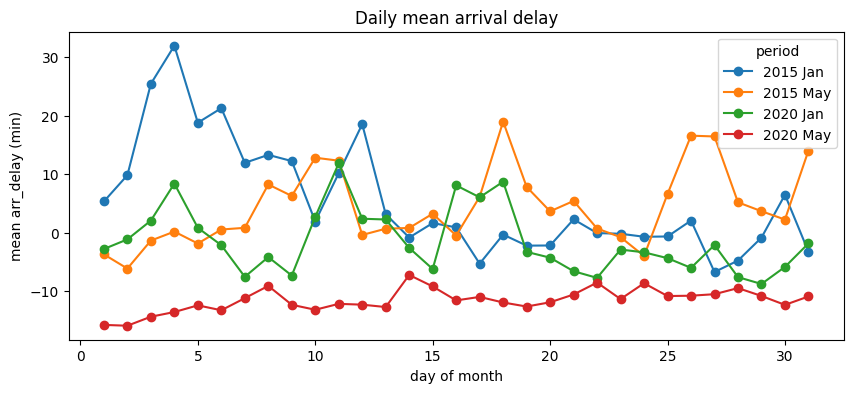

period,2015 Jan,2015 May,2020 Jan,2020 May
day,,,,
1,5.4,-3.7,-2.8,-15.8
2,9.8,-6.1,-1.1,-15.9
3,25.5,-1.3,2.1,-14.4
4,32.0,0.2,8.4,-13.6
5,18.8,-1.8,0.8,-12.4
6,21.3,0.6,-2.1,-13.2
7,12.0,0.8,-7.5,-11.2
8,13.3,8.3,-4.2,-9.1
9,12.3,6.3,-7.3,-12.3


In [75]:
#10. Daily pattern within each period
all_data['day'] = all_data['flight_date'].dt.day
daily = all_data.pivot_table(index='day', columns='period', values='arr_delay')[order]
daily.plot(marker='o', figsize=[10, 4]); plt.ylabel('mean arr_delay (min)'); plt.xlabel('day of month'); plt.title('Daily mean arrival delay'); plt.show()
daily.round(1)

## Part 2

Write a summary of what you find from your data analysis.

## Part 2 Summary of findings

**Scope.** I analysed all four airline files (Jan and May, 2015 and 2020), about 1.75 million flight records. Each file covers only the first 9 days of its month, so the results describe those windows, not whole months or years.

**1. Delays were much lower in 2020 than in 2015.** In January, 40.1% of 2015 flights arrived late (arr_delay > 0) versus 27.0% in January 2020. The share of flights delayed 15+ minutes fell from 21.0% to 13.7%, and the median arrival delay went from -4 to -10 minutes (flights typically arrived early in both years, but more so in 2020). The 2020 January distribution is also more spread out (std 45 vs 39 min, max 2,536 min), so the improvement is in typical flights, not in the worst cases.

**2. May 2020 is a clear COVID-19 outlier.** Flight volume fell from about 497k (May 2015) and 607k (Jan 2020) to about 181k in May 2020. Only 12.5% of flights were late and 4.6% were delayed 15+ minutes, the median flight arrived 14 minutes early, and the standard deviation dropped to 28.5 min. Emptier skies meant fewer delays, but the cancellation rate jumped to 6.4% (vs 1.1% in May 2015 and Jan 2020). Average flight distance also fell (713 vs about 800 miles), consistent with a cut in long-haul schedules. Every carrier except G4 (Allegiant) had a negative mean arrival delay in May 2020.

**3. Winter is worse than spring.** In 2015, January had a higher late rate (40.1%) and far more cancellations (2.5% vs 1.1%) than May, consistent with winter weather. The cancellation rate in Jan 2015 is the highest of the pre-COVID periods.

**4. Departure delay is the key driver of arrival delay.** The correlation between dep_delay and arr_delay is 0.92-0.95 in every period. Distance and elapsed time have almost no correlation with arrival delay (|r| < 0.04), so a flight that leaves late almost always arrives late and flight length does not predict delays.

**5. Causes of delay.** Late-arriving aircraft and carrier-controlled issues account for most delay minutes; weather is the smallest share. Between 2015 and May 2020 the mix shifted away from late-aircraft knock-on delays (about 23 min per delayed flight in Jan 2015 to about 14 min in May 2020) toward carrier delay (about 18 to 32 min). With fewer flights, there is less chain-reaction from one late aircraft to the next. Note this analysis only covers flights delayed 15+ minutes, and May 2020 has only about 7.8k such flights, so its cause averages are based on a much smaller sample.

**6. Carriers and airports.** Carrier rankings are not stable. In January 2015 Delta (-2.0 min mean arrival delay) and Alaska (-0.3) were the best, while Frontier (18.4) and Envoy/American Eagle (MQ, 18.2) were the worst. In May 2020 Alaska and United were best and only Allegiant (G4) averaged a positive delay. Among the 20 busiest origin airports, Chicago O'Hare (17.0 min) and Denver (11.8) stood out in January 2015, versus a system-wide mean of 5.8 min; by May 2020 every one of the top airports shown had flipped to early arrivals on average, with LaGuardia and San Francisco among the earliest.

**Limitations.** (a) Only 9 days per month, so a single storm or event could shift the averages. (b) No scheduled departure time, so I could not examine time-of-day patterns. (c) Cancelled and diverted flights have no arrival delay and are excluded from delay statistics, which flatters periods with many cancellations such as May 2020. (d) Causes are only recorded for flights delayed 15+ minutes. (e) The column `late_aircraft_dealy` is misspelled in the source files; I renamed it to `late_aircraft_delay`.

### Resources

#### Boxplot
https://towardsdatascience.com/understanding-boxplots-5e2df7bcbd51


- matplotlib.pyplot boxplot demo
https://matplotlib.org/3.1.1/gallery/pyplots/boxplot_demo_pyplot.html


#### matplotlib.pyplot
- scatter plot
https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.scatter.html


- histogram plot
https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.hist.html


#### pandas DataFrame
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html


- describe()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.describe.html


- corr()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html


- hist()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html


- plot.scatter()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.plot.scatter.html


- pivot()
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.pivot.html